In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import os, time, shutil, sys
import numpy as np, pandas as pd
from google.colab import drive
drive.mount('/content/drive')



name, memory.total [MiB]
Tesla T4, 15360 MiB
Mounted at /content/drive


In [2]:
SAVE = "/content/drive/MyDrive/hw3_colmap"
COLMAP_RUN = f"{SAVE}/30_exhaustive_SIMPLE_PINHOLE"
assert os.path.exists(f"{COLMAP_RUN}/sparse/0/images.bin"), "COLMAP model not found on Drive"


In [3]:
ZIP = f"{SAVE}/south-building-hw3-subsets-15-30.zip"
if not os.path.exists(ZIP):                      # upload once; kept on Drive afterwards
    from google.colab import files
    up = files.upload()
    shutil.copy(list(up)[0], ZIP)
!unzip -q -o "{ZIP}" -d /content/data
!ls /content/data/images30 | wc -l

Saving south-building-hw3-subsets-15-30.zip to south-building-hw3-subsets-15-30.zip
30


In [4]:
%cd /content
!git clone -q https://github.com/graphdeco-inria/gaussian-splatting
%cd /content/gaussian-splatting
!git submodule update --init --recursive submodules/diff-gaussian-rasterization submodules/simple-knn
!nvcc --version | tail -1
!python -c "import torch; print('torch', torch.__version__, 'cuda', torch.version.cuda)"

!grep -q cstdint submodules/diff-gaussian-rasterization/cuda_rasterizer/rasterizer_impl.h || \
  sed -i '1i #include <cstdint>' submodules/diff-gaussian-rasterization/cuda_rasterizer/rasterizer_impl.h
!grep -q cfloat submodules/simple-knn/simple_knn.cu || sed -i '1i #include <cfloat>' submodules/simple-knn/simple_knn.cu

t0 = time.perf_counter()
!TORCH_CUDA_ARCH_LIST="7.5" pip install -q --no-build-isolation ./submodules/diff-gaussian-rasterization ./submodules/simple-knn
!pip install -q plyfile
print(f"Build time: {(time.perf_counter()-t0)/60:.1f} min")
!python -c "import diff_gaussian_rasterization, simple_knn._C; print('CUDA extensions OK')"

/content
/content/gaussian-splatting
Submodule 'submodules/diff-gaussian-rasterization' (https://github.com/graphdeco-inria/diff-gaussian-rasterization.git) registered for path 'submodules/diff-gaussian-rasterization'
Submodule 'submodules/simple-knn' (https://gitlab.inria.fr/bkerbl/simple-knn.git) registered for path 'submodules/simple-knn'
Cloning into '/content/gaussian-splatting/submodules/diff-gaussian-rasterization'...
Cloning into '/content/gaussian-splatting/submodules/simple-knn'...
Submodule path 'submodules/diff-gaussian-rasterization': checked out '9c5c2028f6fbee2be239bc4c9421ff894fe4fbe0'
Submodule 'third_party/glm' (https://github.com/g-truc/glm.git) registered for path 'submodules/diff-gaussian-rasterization/third_party/glm'
Cloning into '/content/gaussian-splatting/submodules/diff-gaussian-rasterization/third_party/glm'...
Submodule path 'submodules/diff-gaussian-rasterization/third_party/glm': checked out '5c46b9c07008ae65cb81ab79cd677ecc1934b903'
Submodule path 'submo

In [5]:
GS  = "/content/gaussian-splatting"
DST = "/content/gs_data/south30"          # no "360" in the path
OUT = "/content/gs_out/south30"
TEST = ["P1180198.JPG", "P1180208.JPG", "P1180218.JPG"]

shutil.rmtree(DST, ignore_errors=True)
shutil.copytree("/content/data/images30", f"{DST}/images")
shutil.copytree(f"{COLMAP_RUN}/sparse/0", f"{DST}/sparse/0")
with open(f"{DST}/sparse/0/test.txt", "w") as f:
    f.write("\n".join(TEST) + "\n")

all_names = sorted(os.listdir(f"{DST}/images"))
print("Held-out numbers:", [all_names.index(n) + 1 for n in TEST])   # must be [10, 20, 30]

!sed -i 's/train_test_exp, llffhold=8):/train_test_exp, llffhold=0):/' {GS}/scene/dataset_readers.py
!grep -n "def readColmapSceneInfo" {GS}/scene/dataset_readers.py

sys.path.insert(0, GS)
from scene.dataset_readers import readColmapSceneInfo
si = readColmapSceneInfo(DST, "images", "", True, False)
train_names = sorted(c.image_name for c in si.train_cameras)
test_names  = sorted(c.image_name for c in si.test_cameras)
print(len(train_names), "train |", len(test_names), "test:", test_names)

Held-out numbers: [10, 20, 30]
145:def readColmapSceneInfo(path, images, depths, eval, train_test_exp, llffhold=0):
Reading camera 30/30
Converting point3d.bin to .ply, will happen only the first time you open the scene.
27 train | 3 test: ['P1180198.JPG', 'P1180208.JPG', 'P1180218.JPG']


In [6]:
t0 = time.perf_counter()
!cd {GS} && python train.py -s {DST} -m {OUT} --eval --iterations 6000 \
    --save_iterations 2000 6000 --checkpoint_iterations 2000 6000 \
    --test_iterations 2000 6000 --disable_viewer 2>&1 | tee /content/gs_train.log
t_train = time.perf_counter() - t0
print(f"GS training wall time: {t_train/60:.1f} min")
!grep "Evaluating\|Saving" /content/gs_train.log
!ls -lh {OUT} {OUT}/point_cloud

2026-10-05 03:52:36.114303: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Optimizing /content/gs_out/south30
Output folder: /content/gs_out/south30 [05/10 03:52:40]
Reading camera 30/30 [05/10 03:52:41]
Loading Training Cameras [05/10 03:52:41]
Loading Test Cameras [05/10 03:52:44]
Number of points at initialisation :  33207 [05/10 03:52:44]
Training progress: 100%|██████████| 6000/6000 [21:31<00:00,  4.65it/s, Loss=0.0560911, Depth Loss=0.0000000]

[ITER 2000] Evaluating test: L1 0.07431963955362637 PSNR 19.94571749369303 [05/10 03:57:58]

[ITER 2000] Evaluating train: L1 0.03602591268718243 PSNR 24.3357666015625 [05/10 03:58:10]

[ITER 2000] Saving Gaussians [05/10 03:58:11]

[ITER 2000] Saving Checkpoint [05/10 03:58:15]

[ITER 6000] Evaluat

In [7]:
t_render = {}
for it in [2000, 6000]:
    t0 = time.perf_counter()
    !cd {GS} && python render.py -m {OUT} --iteration {it}
    t_render[it] = time.perf_counter() - t0
    print(f"Render @ {it}: {t_render[it]:.1f}s for {len(train_names)+len(test_names)} views")

Looking for config file in /content/gs_out/south30/cfg_args
Config file found: /content/gs_out/south30/cfg_args
Rendering /content/gs_out/south30
Loading trained model at iteration 2000 [05/10 04:15:27]
Reading camera 30/30 [05/10 04:15:28]
Loading Training Cameras [05/10 04:15:28]
Loading Test Cameras [05/10 04:15:30]
Rendering progress: 100% 27/27 [00:35<00:00,  1.30s/it]
Rendering progress: 100% 3/3 [00:04<00:00,  1.47s/it]
Render @ 2000: 49.0s for 30 views
Looking for config file in /content/gs_out/south30/cfg_args
Config file found: /content/gs_out/south30/cfg_args
Rendering /content/gs_out/south30
Loading trained model at iteration 6000 [05/10 04:16:15]
Reading camera 30/30 [05/10 04:16:15]
Loading Training Cameras [05/10 04:16:15]
Loading Test Cameras [05/10 04:16:17]
Rendering progress: 100% 27/27 [00:38<00:00,  1.43s/it]
Rendering progress: 100% 3/3 [00:03<00:00,  1.32s/it]
Render @ 6000: 51.6s for 30 views


In [8]:
!cd {GS} && python metrics.py -m {OUT}          # official: test split only, SSIM/PSNR/LPIPS

import torch
from PIL import Image
import torchvision.transforms.functional as tf
from utils.loss_utils import ssim
from utils.image_utils import psnr

def to_t(p): return tf.to_tensor(Image.open(p))[:3].unsqueeze(0).cuda()

rows = []
with torch.no_grad():
    for split, names in [("train", train_names), ("test", test_names)]:
        for it in [2000, 6000]:
            d = f"{OUT}/{split}/ours_{it}"
            fns = sorted(os.listdir(f"{d}/renders"))
            assert len(fns) == len(names)
            for fn, name in zip(fns, names):
                r, g = to_t(f"{d}/renders/{fn}"), to_t(f"{d}/gt/{fn}")
                rows.append(dict(split=split, iteration=it, image=name,
                                 number=all_names.index(name) + 1,
                                 PSNR=psnr(r, g).mean().item(), SSIM=ssim(r, g).item()))
df = pd.DataFrame(rows)
df.to_csv(f"{SAVE}/gs_metrics_per_view.csv", index=False)

summary = df.groupby(["split", "iteration"])[["PSNR", "SSIM"]].mean().round(4)
print(summary)
print(df[df.split == "test"].pivot(index="number", columns="iteration", values=["PSNR", "SSIM"]).round(3))


Scene: /content/gs_out/south30
Method: ours_6000
Metric evaluation progress:   0% 0/3 [00:00<?, ?it/s]Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth

  0% 0.00/528M [00:00<?, ?B/s]
  2% 11.9M/528M [00:00<00:04, 124MB/s]
  5% 28.8M/528M [00:00<00:03, 154MB/s]
  9% 49.1M/528M [00:00<00:02, 181MB/s]
 13% 69.0M/528M [00:00<00:02, 191MB/s]
 17% 87.4M/528M [00:00<00:02, 184MB/s]
 20% 105M/528M [00:00<00:02, 174MB/s] 
 23% 123M/528M [00:00<00:02, 179MB/s]
 27% 140M/528M [00:00<00:02, 176MB/s]
 30% 157M/528M [00:00<00:02, 168MB/s]
 33% 175M/528M [00:01<00:02, 174MB/s]
 37% 194M/528M [00:01<00:01, 179MB/s]
 40% 213M/528M [00:01<00:01, 185MB/s]
 44% 232M/528M [00:01<00:01, 188MB/s]
 47% 250M/528M [00:01<00:01, 179MB/s]
 51% 269M/528M [00:01<00:01, 185MB/s]
 54% 287M/528M [00:01<00:01, 187MB/s]
 58% 305M/528M [00:01<00:01, 187MB/s]
 61% 323M/528M [00:01<00:01, 187MB/s]
 65% 341M/528M [00:01<00:01, 180MB/s]
 68% 358M/

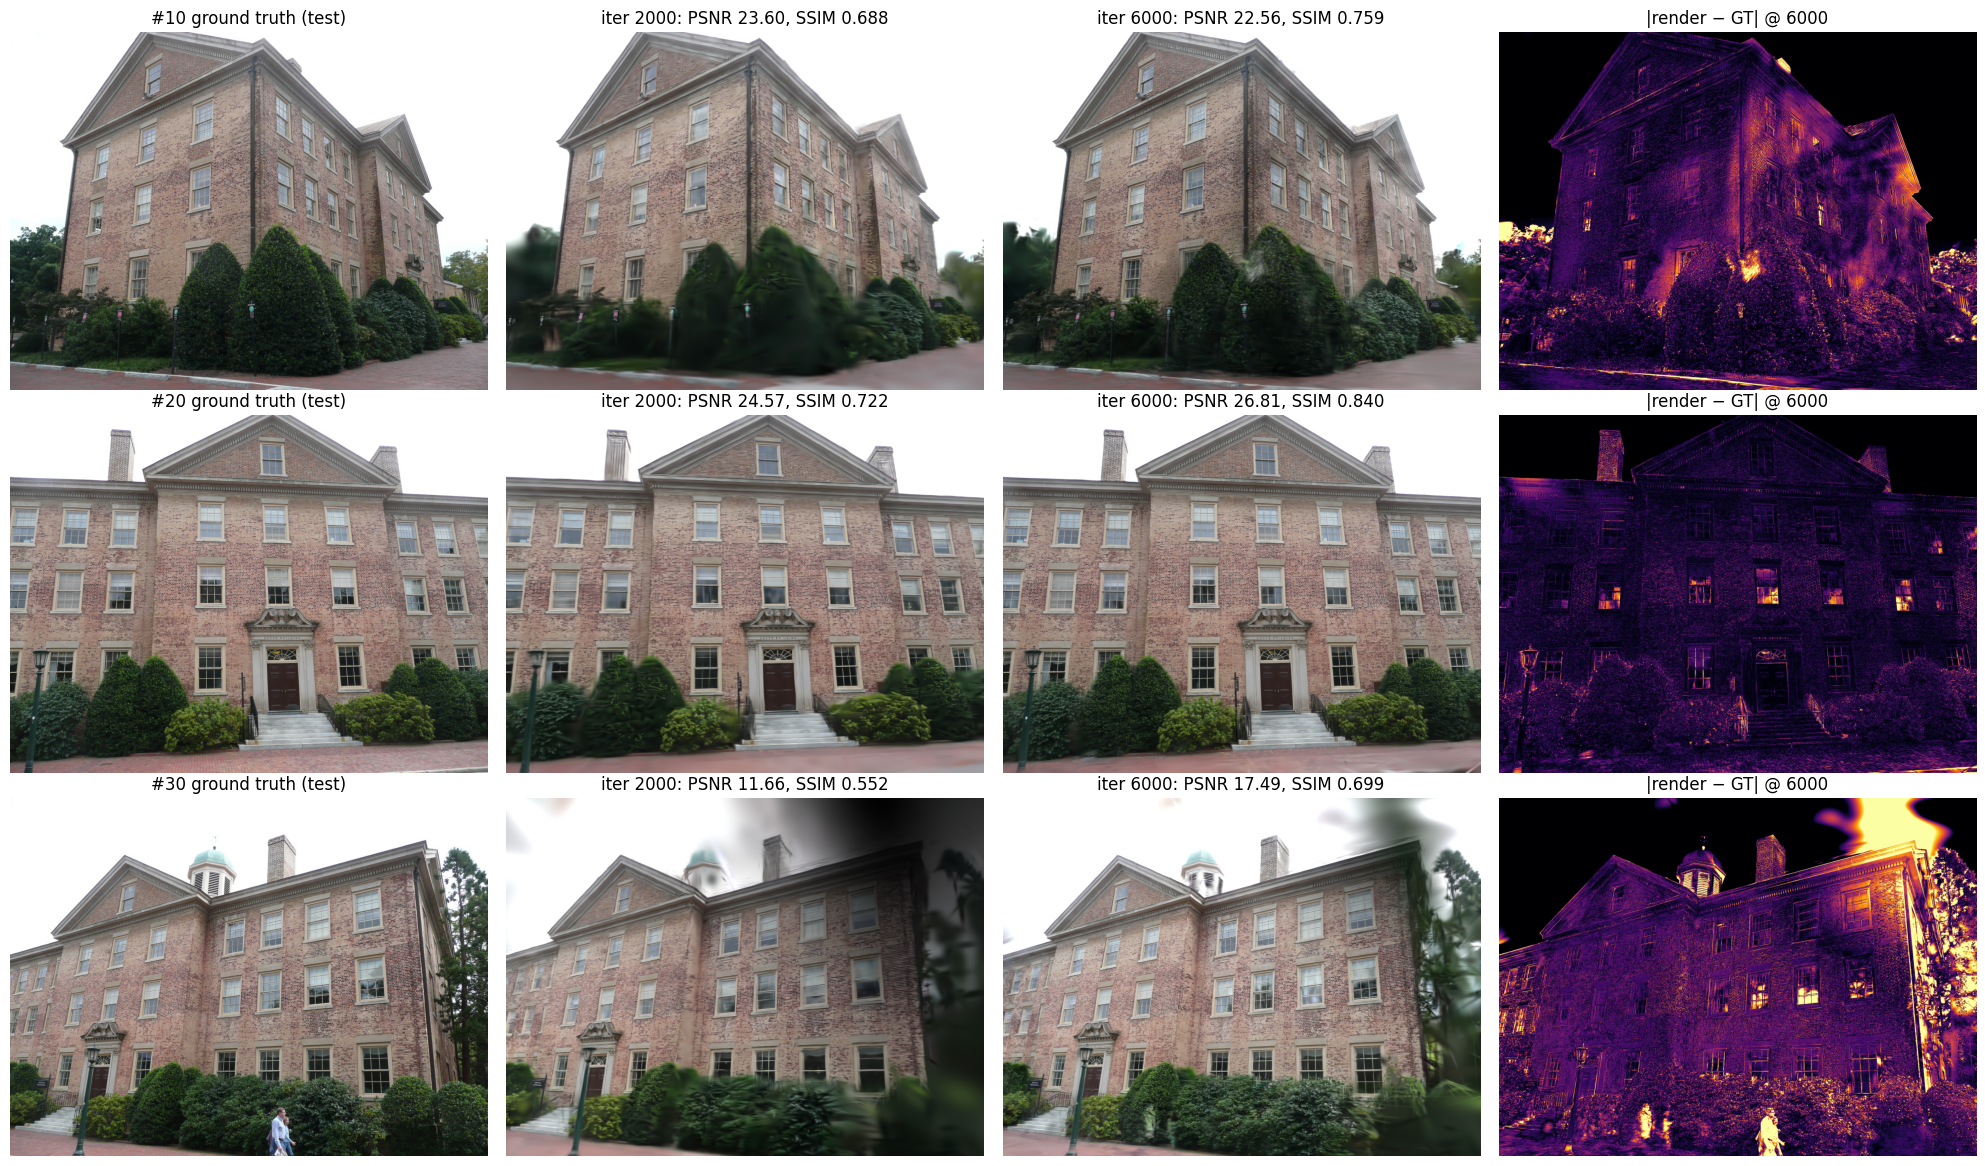

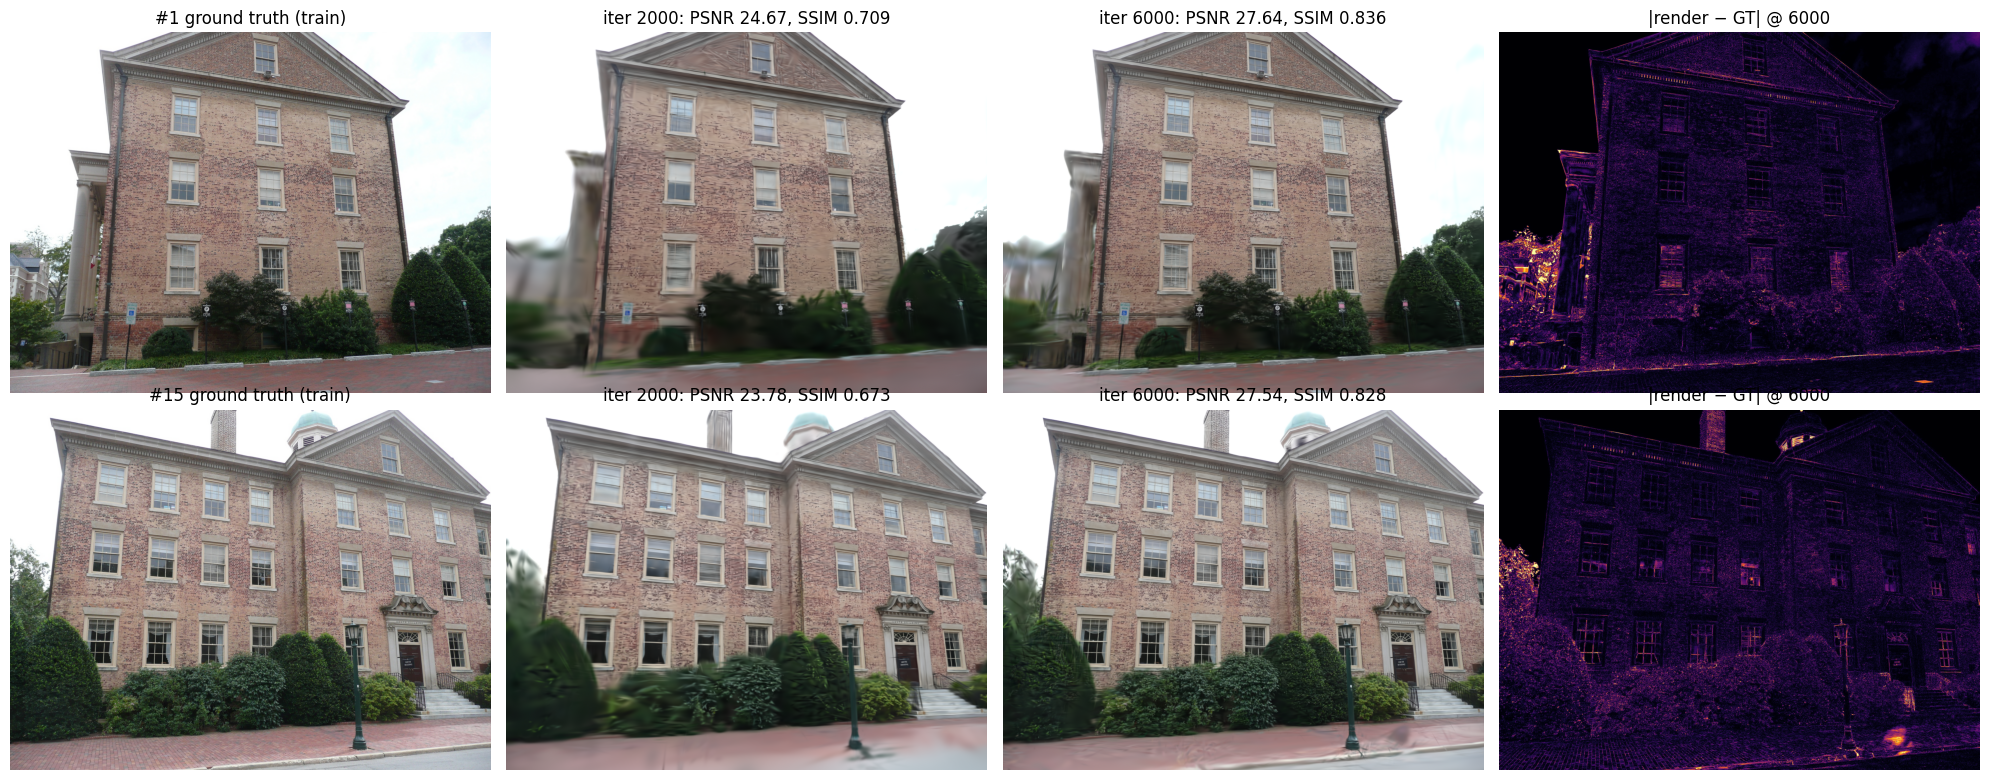

In [9]:
import matplotlib.pyplot as plt

def compare(split, names, picks, fname):
    fig, axes = plt.subplots(len(picks), 4, figsize=(20, 3.9 * len(picks)))
    axes = np.atleast_2d(axes)
    for row, name in zip(axes, picks):
        fn = f"{names.index(name):05d}.png"
        ld = lambda it, kind: np.asarray(Image.open(f"{OUT}/{split}/ours_{it}/{kind}/{fn}"))[..., :3] / 255.
        gt, r2, r6 = ld(6000, "gt"), ld(2000, "renders"), ld(6000, "renders")
        m = df[(df.image == name) & (df.split == split)].set_index("iteration")
        n = all_names.index(name) + 1
        for ax, im, t in zip(row[:3], [gt, r2, r6],
                             [f"#{n} ground truth ({split})",
                              f"iter 2000: PSNR {m.PSNR[2000]:.2f}, SSIM {m.SSIM[2000]:.3f}",
                              f"iter 6000: PSNR {m.PSNR[6000]:.2f}, SSIM {m.SSIM[6000]:.3f}"]):
            ax.imshow(im); ax.set_title(t); ax.axis("off")
        row[3].imshow(np.abs(r6 - gt).mean(-1), cmap="inferno", vmin=0, vmax=0.3)
        row[3].set_title("|render − GT| @ 6000"); row[3].axis("off")
    plt.tight_layout(); plt.savefig(f"{SAVE}/{fname}", dpi=150); plt.show()

compare("test", test_names, test_names, "gs_test_views.png")
compare("train", train_names, [train_names[0], train_names[13]], "gs_train_views.png")

In [10]:
t_colmap = 889.3   # 30-exhaustive total from Part 1 (extract + match + map)
print(f"COLMAP:          {t_colmap/60:.1f} min")
print(f"GS training:     {t_train/60:.1f} min")
for it, t in t_render.items(): print(f"GS render @{it}: {t:.1f} s")
print(f"COLMAP + GS train + render@6000: {(t_colmap + t_train + t_render[6000])/60:.1f} min")

shutil.copytree(OUT, f"{SAVE}/gs_out_south30", dirs_exist_ok=True,
                ignore=shutil.ignore_patterns("*.pth"))
shutil.copy("/content/gs_train.log", SAVE)
!ls -lh {OUT}/*.pth

COLMAP:          14.8 min
GS training:     22.6 min
GS render @2000: 49.0 s
GS render @6000: 51.6 s
COLMAP + GS train + render@6000: 38.3 min
-rw-r--r-- 1 root root 285M Oct  5 03:58 /content/gs_out/south30/chkpnt2000.pth
-rw-r--r-- 1 root root 1.1G Oct  5 04:15 /content/gs_out/south30/chkpnt6000.pth
